# RAG Clínico Seguro con Python, FHIR y Google Gemini

Antes de sumergirte en los módulos prácticos, es fundamental comprender el **contexto arquitectónico, los desafíos y los principios de diseño** que rigen este sistema.

Desarrollar Inteligencia Artificial en el sector salud (Medical Informatics) no es igual que crear un chatbot generalista; aquí las consecuencias de un error o una alucinación pueden comprometer la seguridad del paciente. Por ello, este recorrido técnico se basa en cuatro pilares críticos:

## 1. El Desafío de los Datos Médicos (El Estándar FHIR)

En medicina, la información está fragmentada y es compleja. Las notas de evolución, laboratorios y antecedentes no vienen en párrafos limpios, sino en estructuras complejas o expedientes electrónicos dispersos.

* **La Solución:** Utilizaremos el estándar internacional **FHIR (Fast Healthcare Interoperability Resources)** para normalizar cómo se estructuran y consumen los datos clínicos, permitiendo que la IA entienda recursos específicos del paciente (observaciones, diagnósticos, encuentros).

## 2. Privacidad y Cumplimiento (Privacy-First)

Las normativas internacionales de protección de datos de salud (como HIPAA o regulaciones locales de historia clínica) exigen que los datos sensibles del paciente no queden expuestos ni se utilicen para entrenar modelos públicos sin control.

* **La Solución:** Implementamos una arquitectura híbrida donde las operaciones de búsqueda y vectorización pueden aislarse localmente, utilizando bases de datos vectoriales en memoria y aplicando un estricto control sobre qué información viaja hacia los modelos generativos.

## 3. El Motor del Sistema: RAG (Retrieval-Augmented Generation)

Un LLM por sí solo no conoce el historial médico privado de un paciente. Si le preguntamos directamente, alucinará o dirá que no lo sabe.

* **La Solución:** Combinamos dos mundos mediante una arquitectura RAG:

  1. **Recuperación (Retrieval):** Un sistema matemático basado en **Embeddings** y bases de datos vectoriales (**FAISS**) busca exactamente los párrafos clínicos relevantes en milisegundos.
  2. **Generación (Generation):** Un LLM avanzado (**Google Gemini**) lee exclusivamente esos fragmentos recuperados y redacta una respuesta clínica fundamentada, con restricciones estrictas anti-alucinaciones.

## 4. Gobernanza y Auditoría (LLM-as-a-Judge)

En medicina, confiar ciegamente en una IA es inaceptable. Cada respuesta generada debe ser auditada.

* **La Solución:** Incorporamos capas de validación mediante **esquemas estrictos (Pydantic)** y un segundo modelo auditor que evalúa la fidelidad de la respuesta frente al contexto original antes de que el profesional de la salud la visualice.


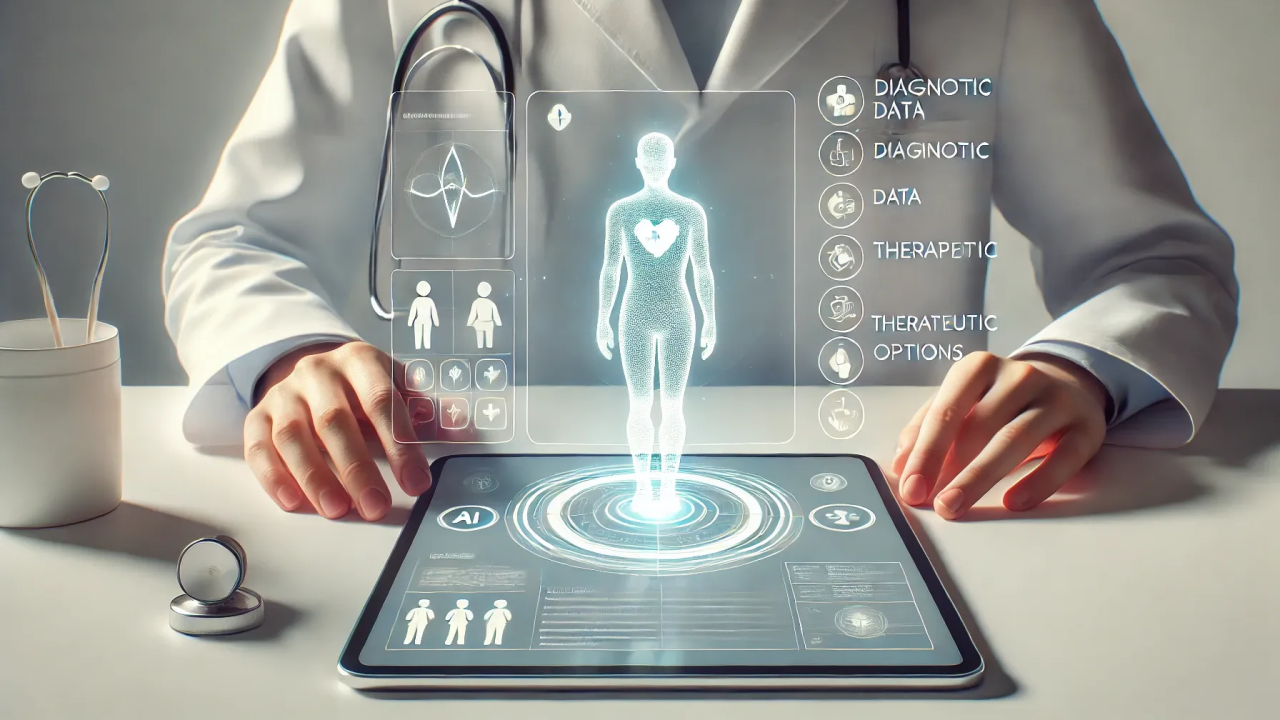

## Fundamentos de LangChain y RAG en el Contexto Médico

El sector salud maneja volúmenes masivos de datos desestructurados (notas clínicas) y estructurados (registros electrónicos). Los Modelos de Lenguaje Grande (LLMs) como Gemini ofrecen capacidades increíbles de razonamiento, pero padecen de dos problemas críticos en entornos médicos: **las alucinaciones clínicas** y la **falta de conocimiento de los datos privados del paciente**.

Aquí es donde entra la **Generación Aumentada por Recuperación (Retrieval-Augmented Generation o RAG)**. La arquitectura RAG no entrena al modelo con datos médicos privados; en su lugar, le proporciona contexto relevante (como el historial reciente del paciente) en tiempo de ejecución antes de que genere una respuesta.

**LangChain** es el framework orquestador que nos permitirá construir este flujo (*pipeline*). Actúa como el pegamento entre el modelo de lenguaje, las bases de datos y la lógica de negocio.

### El Desafío: RAG Básico vs. Estándares Médicos (FHIR)

Un pipeline RAG típico lee documentos PDF o texto plano. Sin embargo, en medicina, el estándar de interoperabilidad global es **FHIR (Fast Healthcare Interoperability Resources)**. FHIR estructura los datos en formato JSON bajo recursos específicos (como `Patient`, `Observation`, `Condition`).

Nuestro objetivo a lo largo de este recorrido será construir un sistema RAG que no solo entienda texto médico, sino que pueda ingerir, procesar y consultar datos estructurados FHIR utilizando LangChain, culminando en la evaluación de la precisión clínica de sus respuestas.

En esta primera etapa, estableceremos la conexión fundamental con `gemini` utilizando LangChain, asegurando que nuestra infraestructura base funcione correctamente antes de introducir datos complejos de salud.


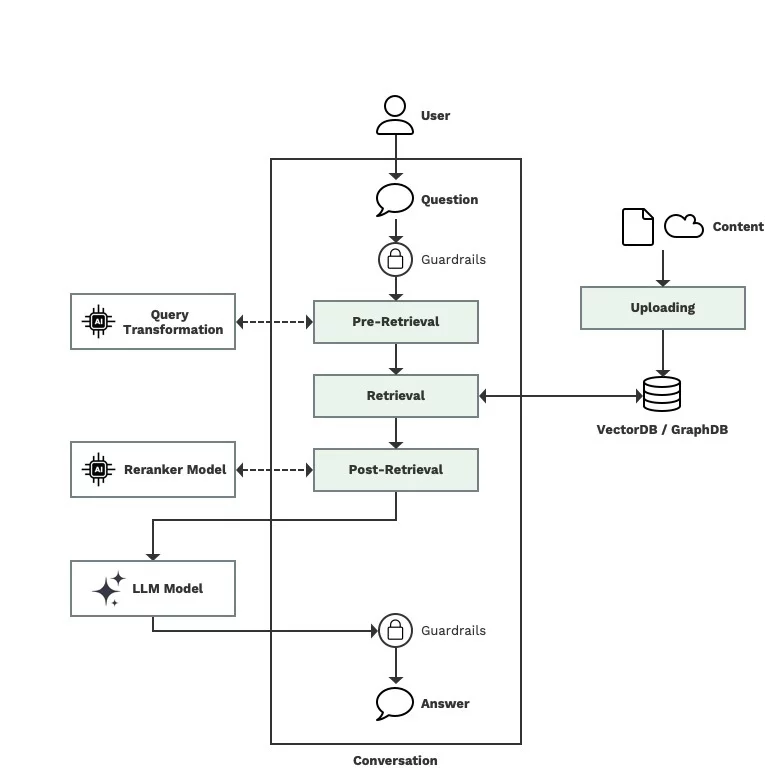

In [1]:
!pip install -q langchain-google-genai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.2/74.2 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.0/570.0 kB 4.9 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.5.5
    Uninstalling langchain-core-1.5.5:
      Successfully uninstalled langchain-core-1.5.5


In [2]:
import os
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")
    print("Asegúrate de configurar 'GOOGLE_API_KEY' en los secretos de Colab.")

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.2
)

instruccion = (
    "Actúa como un arquitecto de software médico. Explica brevemente, en formato "
    "de 3 viñetas, por qué el estándar FHIR es crucial para los sistemas modernos de salud."
)

print("\nEnviando instrucción al modelo Gemini...")

try:
    respuesta = llm.invoke(instruccion)

    # 4. Extracción y visualización del resultado
    print("\n=== RESPUESTA DEL MODELO (Texto Limpio) ===")

    # Verificamos si la respuesta viene en formato de lista (nueva versión) o como texto simple (versión clásica)
    if isinstance(respuesta.content, list):
      # Extraemos el valor de la clave 'text' del primer elemento de la lista
      texto_limpio = respuesta.content[0]['text']
    else:
    # Si ya es un texto simple, lo dejamos tal cual
      texto_limpio = respuesta.content

    print(texto_limpio)

except Exception as e:
    print(f"\n❌ Error durante la invocación del modelo: {e}")



✅ Credenciales configuradas exitosamente.

Enviando instrucción al modelo Gemini...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3237: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



=== RESPUESTA DEL MODELO (Texto Limpio) ===
Como arquitecto de software médico, te lo resumo en tres pilares fundamentales que hacen de FHIR (Fast Healthcare Interoperability Resources) el estándar de oro actual:

*   **Interoperabilidad nativa y moderna:** A diferencia de los estándares antiguos y complejos (como HL7 v2 o CDA), FHIR se basa en tecnologías web estándar (RESTful APIs, JSON, XML y OAuth). Esto permite que aplicaciones móviles, historiales clínicos electrónicos (EHR) y dispositivos IoT se comuniquen entre sí de forma tan sencilla como lo hacen las aplicaciones modernas de consumo (como Google o Uber).
*   **Modelo modular basado en "Recursos":** Desglosa la información clínica en bloques lógicos independientes y reutilizables llamados recursos (ej. *Patient*, *Observation*, *Medication*). Esto da una gran flexibilidad arquitectónica, permitiendo a los sistemas consultar y compartir únicamente los datos precisos que necesitan sin sobrecargar la red ni procesar documentos 

##Extracción y Preprocesamiento de Recursos Estructurados FHIR

Para que nuestro sistema RAG (Generación Aumentada por Recuperación) funcione en un hospital real, no podemos simplemente pasarle PDFs. Debemos interactuar con el estándar **FHIR (Fast Healthcare Interoperability Resources)**.

En FHIR, la información clínica no es un bloque de texto libre; está estructurada en formato **JSON** mediante "Recursos" (Resources). Por ejemplo:

* Un recurso `Patient` guarda los datos demográficos.
* Un recurso `Condition` guarda los diagnósticos.
* Un recurso `Observation` guarda los signos vitales o resultados de laboratorio.

### El Reto del Preprocesamiento para RAG

A los Modelos de Lenguaje (LLMs) se les da muy bien leer texto natural. Si le pasamos un JSON crudo gigante, gastaremos muchos "tokens" (costo) en llaves `{ }` y comillas `" "`, y el modelo puede confundirse.

La mejor práctica en **RAG Médico** es extraer los datos clave del JSON de FHIR y transformarlos en **"Documentos de Texto Narrativo"** antes de vectorizarlos. En este módulo, simularemos la llegada de un recurso FHIR y lo procesaremos con Python puro antes de pasarlo a LangChain.


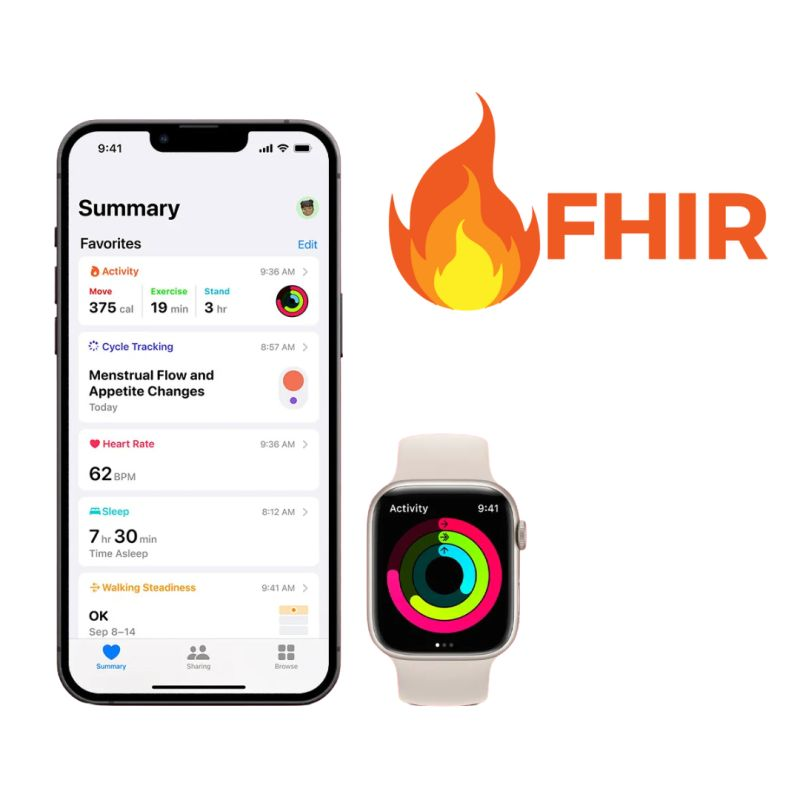

In [3]:
import json
# Importamos la clase Document de LangChain.
# LangChain requiere que todo el texto externo esté envuelto en objetos 'Document'
# para poder gestionarlos en las siguientes fases (Chunking y Vectorización).
from langchain_core.documents import Document

# En la vida real, obtendrías este JSON haciendo una petición a una API REST (ej. un servidor HAPI FHIR).
# Aquí lo simulamos como un diccionario de Python.
# Un 'Bundle' en FHIR es un paquete que contiene múltiples recursos médicos.
datos_fhir_simulados = {
    "resourceType": "Bundle",
    "type": "collection",
    "entry": [
        {
            "resource": {
                "resourceType": "Patient",
                "id": "pat-123",
                "name": [{"given": ["Juan"], "family": "Pérez"}],
                "gender": "male",
                "birthDate": "1965-04-12"
            }
        },
        {
            "resource": {
                "resourceType": "Condition",
                "id": "cond-456",
                "subject": {"reference": "Patient/pat-123"},
                "code": {
                    "coding": [{"system": "http://hl7.org/fhir/sid/icd-10", "code": "E11.9", "display": "Diabetes mellitus tipo 2 sin complicaciones"}]
                },
                "clinicalStatus": {"coding": [{"code": "active"}]}
            }
        }
    ]
}

def procesar_bundle_fhir(fhir_data):
    """
    Toma un Bundle de FHIR en formato JSON (diccionario) y lo convierte
    en una lista de objetos Document de LangChain con texto narrativo.
    """
    documentos_langchain = []

    for entry in fhir_data.get("entry", []):
        recurso = entry.get("resource", {})
        tipo_recurso = recurso.get("resourceType", "Desconocido")

        # Lógica de extracción dependiendo del tipo de recurso médico
        if tipo_recurso == "Patient":
            # Extraemos el nombre con seguridad (por si falta algún dato)
            nombre = recurso.get("name", [{}])[0].get("given", [""])[0]
            apellido = recurso.get("name", [{}])[0].get("family", "")

            # Construimos la narrativa clínica
            texto_narrativo = f"Paciente: {nombre} {apellido}. Género: {recurso.get('gender')}. Fecha de nacimiento: {recurso.get('birthDate')}."

        elif tipo_recurso == "Condition":
            # Extraemos el diagnóstico
            diagnostico = recurso.get("code", {}).get("coding", [{}])[0].get("display", "Sin diagnóstico")
            estado = recurso.get("clinicalStatus", {}).get("coding", [{}])[0].get("code", "desconocido")

            # Construimos la narrativa
            texto_narrativo = f"Condición Médica: {diagnostico}. Estado clínico: {estado}. Paciente de referencia: {recurso.get('subject', {}).get('reference')}."

        else:
            texto_narrativo = f"Recurso de tipo {tipo_recurso} no procesado."

        doc = Document(
            page_content=texto_narrativo,
            metadata={"source": "FHIR_API", "resource_id": recurso.get("id"), "resource_type": tipo_recurso}
        )
        documentos_langchain.append(doc)

    return documentos_langchain

print("Procesando datos FHIR...")
documentos_procesados = procesar_bundle_fhir(datos_fhir_simulados)

print("\n=== DOCUMENTOS LISTOS PARA LANGCHAIN ===")
for doc in documentos_procesados:
    print(f"📄 Contenido: {doc.page_content}")
    print(f"🔗 Metadatos: {doc.metadata}\n")

Procesando datos FHIR...

=== DOCUMENTOS LISTOS PARA LANGCHAIN ===
📄 Contenido: Paciente: Juan Pérez. Género: male. Fecha de nacimiento: 1965-04-12.
🔗 Metadatos: {'source': 'FHIR_API', 'resource_id': 'pat-123', 'resource_type': 'Patient'}

📄 Contenido: Condición Médica: Diabetes mellitus tipo 2 sin complicaciones. Estado clínico: active. Paciente de referencia: Patient/pat-123.
🔗 Metadatos: {'source': 'FHIR_API', 'resource_id': 'cond-456', 'resource_type': 'Condition'}



## Fragmentación Estratégica de Contexto Clínico (Chunking)

En la fase anterior logramos extraer información estructurada (JSON) y convertirla en texto narrativo. Para recursos cortos como `Patient` o diagnósticos breves de `Condition`, esto funciona perfecto.

Sin embargo, en el mundo real de FHIR, existen recursos como `DiagnosticReport` o `DocumentReference` (notas de evolución, informes de biopsias, epicrisis) que contienen miles de palabras. Si enviamos textos gigantescos al proceso de vectorización, enfrentaremos dos problemas:

1. **Pérdida de foco (Lost in the middle):** Los LLMs tienden a olvidar la información que está en el medio de un documento muy largo.
2. **Ruido en la recuperación:** Si un "chunk" (fragmento) es muy grande y abarca 5 temas clínicos distintos, la búsqueda por similitud perderá precisión.

El **Chunking** es el arte de dividir textos largos en fragmentos más pequeños y manejables, manteniendo el contexto semántico. En LangChain, la herramienta más recomendada es el `RecursiveCharacterTextSplitter`, que intenta dividir por párrafos, luego por oraciones y finalmente por palabras, preservando la cohesión estructural del texto médico. Además, utilizamos un **traslape (overlap)** para no cortar ideas o términos médicos complejos por la mitad.


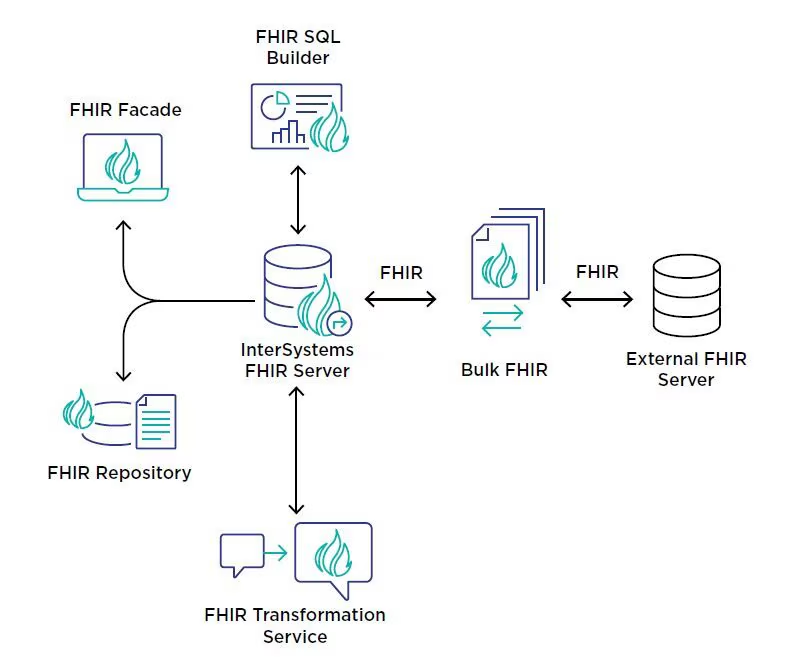

In [4]:
!pip install -q langchain-text-splitters langchain-core

In [5]:
# =====================================================================
# Práctica: Fragmentación de Historias Clínicas Extensas (Chunking)
# =====================================================================

# Importamos la herramienta de LangChain diseñada para dividir texto de manera inteligente.
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document

# =====================================================================
# Práctica: Fragmentación de Historias Clínicas Extensas (Chunking)
# =====================================================================

# Importamos la herramienta de LangChain diseñada para dividir texto de manera inteligente.
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document

# ---------------------------------------------------------
# 1. Nota Clínica Extensa (DocumentReference)
# ---------------------------------------------------------
# Texto narrativo que podríamos haber extraído de un recurso FHIR
# de tipo 'DocumentReference' (ej. una nota de alta médica o epicrisis).
nota_clinica_extensa = """
Paciente de 61 años ingresa a urgencias presentando disnea de esfuerzo de dos semanas de evolución,
acompañada de dolor torácico opresivo que irradia a brazo izquierdo.
Antecedentes familiares de cardiopatía isquémica (padre falleció de IAM a los 58 años).
El paciente tiene antecedentes personales de hipertensión arterial crónica, tratada con Losartán 50mg/día,
y diabetes mellitus tipo 2, controlada con Metformina 850mg/día.

Durante la exploración física, presenta presión arterial de 150/90 mmHg, frecuencia cardíaca de 98 lpm,
y saturación de oxígeno del 94% al aire ambiente. A la auscultación cardiopulmonar, se escuchan
crepitantes bibasales finos. El electrocardiograma (ECG) revela supradesnivel del segmento ST
en derivaciones V1 a V4.

Se decide administrar terapia antiagregante plaquetaria de inmediato (Aspirina 300mg y Clopidogrel 300mg)
y se traslada al paciente a la unidad de hemodinamia para angiografía coronaria de urgencia.
El diagnóstico presuntivo es Infarto Agudo de Miocardio con Elevación del ST (IAMCEST) de pared anterior.
"""

documento_clinico = Document(
    page_content=nota_clinica_extensa,
    metadata={"source": "FHIR_DocumentReference", "patient_id": "pat-123"}
)

divisor_texto = RecursiveCharacterTextSplitter(
    chunk_size=350,       # Tamaño moderado para mantener conceptos clínicos juntos
    chunk_overlap=50,     # Traslape de 50 caracteres
    length_function=len,  # Usamos la longitud estándar de Python
)

# Ejecutamos el método split_documents que toma una lista de documentos
# y devuelve una nueva lista con los documentos fragmentados.
print("Iniciando proceso de fragmentación (Chunking)...")
documentos_fragmentados = divisor_texto.split_documents([documento_clinico])

# --------------------

print(f"\nSe generaron {len(documentos_fragmentados)} fragmentos a partir del texto original.\n")
print("=== CHUNKS GENERADOS ===")

# Iteramos para ver cómo LangChain cortó el texto
for i, chunk in enumerate(documentos_fragmentados, 1):
    print(f"--- Fragmento {i} ---")
    print(f"Contenido: {chunk.page_content}")
    # Nota de aprendizaje: Observa cómo los metadatos se duplican automáticamente
    # en cada chunk, así no perdemos el rastro de a qué paciente pertenece esta información.
    print(f"Metadatos: {chunk.metadata}\n")
    print(f"Longitud: {len(chunk.page_content)} caracteres")
    print("-" * 30 + "\n")

Iniciando proceso de fragmentación (Chunking)...

Se generaron 4 fragmentos a partir del texto original.

=== CHUNKS GENERADOS ===
--- Fragmento 1 ---
Contenido: Paciente de 61 años ingresa a urgencias presentando disnea de esfuerzo de dos semanas de evolución, 
acompañada de dolor torácico opresivo que irradia a brazo izquierdo. 
Antecedentes familiares de cardiopatía isquémica (padre falleció de IAM a los 58 años).
Metadatos: {'source': 'FHIR_DocumentReference', 'patient_id': 'pat-123'}

Longitud: 258 caracteres
------------------------------

--- Fragmento 2 ---
Contenido: El paciente tiene antecedentes personales de hipertensión arterial crónica, tratada con Losartán 50mg/día, 
y diabetes mellitus tipo 2, controlada con Metformina 850mg/día.
Metadatos: {'source': 'FHIR_DocumentReference', 'patient_id': 'pat-123'}

Longitud: 172 caracteres
------------------------------

--- Fragmento 3 ---
Contenido: Durante la exploración física, presenta presión arterial de 150/90 mmHg, frecuenci

## Generación de Representaciones Vectoriales (Embeddings Médicos)

Hasta este punto, hemos extraído datos de un estándar complejo (FHIR) y los hemos fragmentado en pequeños "trozos" legibles (*Chunks*). Sin embargo, los algoritmos de Inteligencia Artificial no entienden español, inglés, ni terminología médica; **solo entienden números**.

Aquí es donde entran los **Embeddings** (Incrustaciones). Un modelo de embeddings es una red neuronal especializada en leer un texto y convertirlo en una larga lista de números (un vector de alta dimensionalidad).

¿Por qué esto es revolucionario en la medicina?
En los sistemas de bases de datos tradicionales, si buscas *"hipertensión"*, el sistema busca exactamente esa palabra (búsqueda léxica). Si la nota del médico dice *"presión arterial alta"*, no la encontrará.
Los embeddings, en cambio, mapean los textos en un espacio matemático donde **los conceptos con significado clínico similar están físicamente cerca**. Así, el vector de *"hipertensión"* y el vector de *"presión arterial alta"* serán casi idénticos, permitiendo una **búsqueda semántica**.

En este ejercicio, utilizaremos el modelo de embeddings de Google para convertir nuestros fragmentos clínicos en coordenadas matemáticas.


In [6]:
from google import genai
client = genai.Client()

textos_clinicos = [
    "El paciente presenta hipertensión arterial severa.",
    "Se observa una presión sanguínea peligrosamente alta en el sujeto.",
    "Paciente con fractura transversal de tibia izquierda."
]

print("Conectando con la API nativa de Google GenAI para generar vectores...\n")

vectores_generados = []

for texto in textos_clinicos:
    resultado = client.models.embed_content(
        model="gemini-embedding-2",
        contents=texto
    )
    # Extraemos específicamente la lista de números (el embedding real)
    vectores_generados.append(resultado.embeddings[0].values)

print("=== ANATOMÍA DEL VECTOR GENERADO ===")

# Seleccionamos el vector de nuestro primer texto clínico ("hipertensión")
vector_ejemplo = vectores_generados[0]

# La "longitud" o dimensión del vector determina qué tan detallada es la
# representación semántica del concepto médico.
dimension = len(vector_ejemplo)
print(f"Dimensiones del modelo de Google: {dimension} números por cada texto.")

# Mostramos solo los primeros 5 números para no saturar la pantalla.
# Estos números representan "coordenadas" abstractas en el espacio semántico.
print(f"Muestra matemática (primeras 5 dimensiones): {vector_ejemplo[:5]}")

Conectando con la API nativa de Google GenAI para generar vectores...

=== ANATOMÍA DEL VECTOR GENERADO ===
Dimensiones del modelo de Google: 3072 números por cada texto.
Muestra matemática (primeras 5 dimensiones): [-0.0034485513, -0.011032346, -0.0028598388, -0.0052252156, -0.00041708187]


## Implementación de Almacenes Vectoriales (Vector Stores) Corporativos

Ahora que sabemos cómo convertir texto clínico en vectores matemáticos (Embeddings), nos enfrentamos a un problema de escala. Un hospital de tamaño medio genera miles de notas clínicas al día. Si queremos buscar el historial de un paciente, no podemos comparar nuestra pregunta matemáticamente con cada una de las notas, una por una; tomaría demasiado tiempo.

Aquí es donde entran los **Vector Stores (Bases de Datos Vectoriales)**.

Un Vector Store no guarda la información en tablas y columnas (como SQL). Guarda los **vectores (las coordenadas espaciales)** y el **texto original** en un índice matemático optimizado. Cuando el médico hace una pregunta, la base de datos convierte la pregunta en un vector y realiza una búsqueda de similitud (usualmente *Similitud del Coseno*) para encontrar los vectores más cercanos en el hiperespacio en milisegundos.

Ejemplos de estas bases de datos son **Pinecone** (en la nube), **ChromaDB** o **FAISS** (ejecución local). En este módulo de grado médico, usaremos **FAISS (Facebook AI Similarity Search)**, que nos permite mantener todos los datos estructurados en la memoria local de nuestro servidor, garantizando la privacidad del paciente y operaciones ultrarrápidas.

*(Nota preparatoria: Antes de ejecutar el código, asegúrate de tener instalada la librería FAISS ejecutando en una celda previa:* *`!pip install faiss-cpu langchain-community`**)*


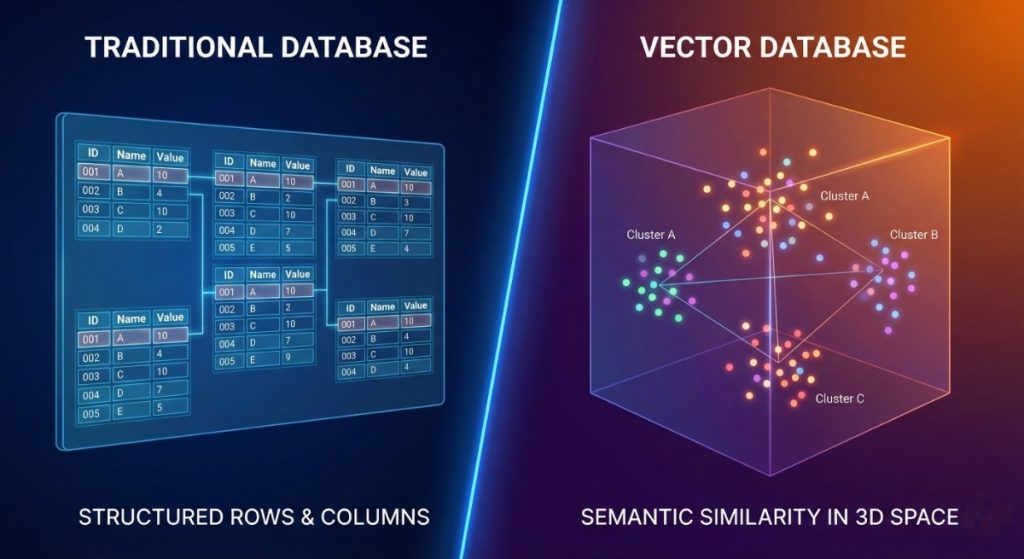

In [7]:
!pip install -q faiss-cpu langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [9]:
from google import genai
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
# Importamos la clase base de LangChain para crear nuestro propio integrador
from langchain_core.embeddings import Embeddings

# LangChain necesita que los modelos de embeddings tengan dos métodos obligatorios:
# 'embed_documents' (para listas de textos) y 'embed_query' (para una sola pregunta).
class GoogleNativeEmbeddings(Embeddings):
    def __init__(self, model_name="gemini-embedding-2"):
        # Inicializamos el cliente nativo que definimos en el Módulo 4
        self.client = genai.Client()
        self.model = model_name

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        """Convierte una lista de textos clínicos en una lista de vectores."""
        vectores = []
        for text in texts:
            resultado = self.client.models.embed_content(
                model=self.model,
                contents=text
            )
            vectores.append(resultado.embeddings[0].values)
        return vectores

    def embed_query(self, text: str) -> list[float]:
        """Convierte la pregunta del médico en un vector único."""
        resultado = self.client.models.embed_content(
            model=self.model,
            contents=text
        )
        return resultado.embeddings[0].values

print("Cargando motor de embeddings nativo de Google...")
modelo_embeddings_google = GoogleNativeEmbeddings()


fragmentos_clinicos = [
    Document(
        page_content="Paciente refiere dolor torácico opresivo que irradia al brazo izquierdo. Posible IAM.",
        metadata={"patient_id": "111", "especialidad": "cardiologia"}
    ),
    Document(
        page_content="Fractura expuesta de fémur derecho tras accidente de tránsito.",
        metadata={"patient_id": "222", "especialidad": "traumatologia"}
    ),
    Document(
        page_content="Paciente con niveles de glucosa en ayunas de 210 mg/dL. Se ajusta dosis de insulina.",
        metadata={"patient_id": "333", "especialidad": "endocrinologia"}
    ),
    Document(
        page_content="Presenta presión arterial de 160/100 mmHg y taquicardia leve.",
        metadata={"patient_id": "111", "especialidad": "cardiologia"}
    )
]

print("Indexando documentos médicos en la base vectorial FAISS...")

# LangChain usará internamente nuestra clase 'GoogleNativeEmbeddings'
# para vectorizar todos los fragmentos.
base_vectorial = FAISS.from_documents(
    documents=fragmentos_clinicos,
    embedding=modelo_embeddings_google
)
print("✅ Base de datos vectorial construida con éxito.\n")

pregunta_medico = "¿Hay algún paciente con problemas del corazón?"
print(f"🔍 Búsqueda del médico: '{pregunta_medico}'")

# Extraemos los 2 documentos matemáticamente más cercanos a la pregunta.
resultados = base_vectorial.similarity_search(
    query=pregunta_medico,
    k=2
)

print("\n=== RESULTADOS RECUPERADOS (RAG - Fase R) ===")
for i, doc in enumerate(resultados, 1):
    print(f"Resultado #{i}:")
    print(f"📝 Nota Clínica: {doc.page_content}")
    print(f"📊 Metadatos: {doc.metadata}")
    print("-" * 40)

Cargando motor de embeddings nativo de Google...
Indexando documentos médicos en la base vectorial FAISS...
✅ Base de datos vectorial construida con éxito.

🔍 Búsqueda del médico: '¿Hay algún paciente con problemas del corazón?'

=== RESULTADOS RECUPERADOS (RAG - Fase R) ===
Resultado #1:
📝 Nota Clínica: Paciente refiere dolor torácico opresivo que irradia al brazo izquierdo. Posible IAM.
📊 Metadatos: {'patient_id': '111', 'especialidad': 'cardiologia'}
----------------------------------------
Resultado #2:
📝 Nota Clínica: Presenta presión arterial de 160/100 mmHg y taquicardia leve.
📊 Metadatos: {'patient_id': '111', 'especialidad': 'cardiologia'}
----------------------------------------


## Recuperación Aumentada (Retrieval) y Cadenas Generativas (LCEL)

¡Llegamos al núcleo de nuestra arquitectura! Hasta ahora tenemos dos mundos separados:

1. **El Médico Analista:** Nuestro LLM (`gemini`) capaz de razonar.
2. **El Sistema de Archivos:** Nuestra base de datos vectorial (FAISS) que busca datos médicos precisos basados en matemáticas (Embeddings).

En este módulo, vamos a fusionarlos. Para ello utilizaremos **LCEL (LangChain Expression Language)**. LCEL es una sintaxis moderna y declarativa que utiliza el símbolo de "tubería" o *pipe* (`|`) para conectar componentes, pasando la salida de un paso como entrada del siguiente.

### La Anatomía de una Cadena RAG con LCEL

Nuestra cadena tendrá este flujo exacto:

1. **Pregunta:** El usuario pregunta algo.
2. **Retrieval (R):** La base de datos (FAISS) busca los *chunks* relevantes.
3. **Prompting:** Inyectamos esos *chunks* (Contexto) y la Pregunta en una plantilla estricta de instrucciones (Prompt Template).
4. **Generation (G):** El LLM lee el contexto, razona y genera una respuesta segura.
5. **Output Parser:** Limpiamos la salida para que sea texto puro y legible.

La clave de un RAG médico exitoso es el **Prompt Anti-Alucinaciones**: le ordenaremos al LLM que *solo* responda basado en el contexto proporcionado.


In [10]:
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
from langchain_google_genai import ChatGoogleGenerativeAI

recuperador = base_vectorial.as_retriever(search_kwargs={"k": 2})

plantilla_medica = """Actúa como un asistente clínico experto y preciso.
Utiliza ÚNICAMENTE el siguiente contexto (extraído de notas clínicas FHIR) para responder a la pregunta.
Si la información no está explícitamente en el contexto, responde: "No dispongo de esa información en el historial clínico actual."
NO inventes medicamentos, diagnósticos ni datos del paciente.

Contexto Recuperado:
{context}

Pregunta del Profesional: {question}

Respuesta Clínica:"""

# Convertimos el texto en un objeto PromptTemplate de LangChain
prompt = PromptTemplate.from_template(plantilla_medica)

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.0
)

def formatear_documentos(docs):
    """
    Toma la lista de documentos que devuelve el Retriever y extrae solo
    el texto (page_content), uniéndolo con saltos de línea para inyectarlo en el prompt.
    """
    return "\n\n".join(doc.page_content for doc in docs)

print("Construyendo la tubería RAG (LCEL)...")

cadena_rag = (
    {"context": recuperador | formatear_documentos, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser() # Nos ahorra hacer el condicional del isinstance() que vimos en el Módulo 1
)

print("✅ Cadena RAG lista para producción.\n")

# Hagamos dos pruebas. Una que debería responder con el contexto,
# y otra que debería activar nuestra protección anti-alucinaciones.

pregunta_1 = "¿Qué síntomas presenta el paciente con posibles problemas cardíacos?"
pregunta_2 = "¿El paciente es alérgico a la penicilina?"

print(f"👨‍⚕️ Médico: {pregunta_1}")
# Usamos .invoke() para ejecutar todo el pipeline de principio a fin.
respuesta_1 = cadena_rag.invoke(pregunta_1)
print(f"🤖 Asistente RAG:\n{respuesta_1}\n")
print("-" * 50 + "\n")

print(f"👨‍⚕️ Médico: {pregunta_2}")
respuesta_2 = cadena_rag.invoke(pregunta_2)
print(f"🤖 Asistente RAG:\n{respuesta_2}")

Construyendo la tubería RAG (LCEL)...
✅ Cadena RAG lista para producción.

👨‍⚕️ Médico: ¿Qué síntomas presenta el paciente con posibles problemas cardíacos?
🤖 Asistente RAG:
El paciente presenta los siguientes síntomas y hallazgos clínicos asociados a un posible problema cardíaco (posible IAM):

* **Dolor torácico opresivo** que se irradia al brazo izquierdo.
* **Presión arterial de 160/100 mmHg**.
* **Taquicardia leve**.

--------------------------------------------------

👨‍⚕️ Médico: ¿El paciente es alérgico a la penicilina?
🤖 Asistente RAG:
No dispongo de esa información en el historial clínico actual.


## Optimización de Prompts y Gestión del Contexto para Evitar Alucinaciones

Hasta este punto, hemos construido un pipeline RAG funcional utilizando FAISS, nuestros embeddings de Google y una cadena LCEL con Gemini. Sin embargo, en un entorno hospitalario real, nos enfrentamos a un desafío crítico: **la saturación de la ventana de contexto y los sesgos cognitivos del modelo.**

Cuando un paciente tiene años de historial médico, el retriever (FAISS) podría traer 10 o 15 fragmentos largos. Esto genera dos problemas graves:

1. **El fenómeno "Lost in the Middle":** Los LLMs prestan muchísima atención al inicio y al final del texto que se les envía, pero tienden a "olvidar" o restar importancia a la información crítica que queda enterrada en el medio del contexto.
2. **Exceso de ruido clínico:** Si incluimos notas irrelevantes (por ejemplo, antecedentes de traumatología de hace 5 años cuando se busca un diagnóstico cardiológico agudo), el modelo puede distraerse y generar una alucinación clínica.

### Técnicas Avanzadas de Optimización en este Módulo:

* **Filtros por Metadatos Clínicos:** En lugar de buscar a ciegas en todo el historial, utilizaremos los metadatos del estándar FHIR (como `especialidad` o `patient_id`) para restringir la búsqueda antes de calcular los embeddings.
* **Control de Temperatura y Penalizaciones:** Ajustaremos los parámetros de inferencia para asegurar un comportamiento determinista.


In [11]:
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
from langchain_google_genai import ChatGoogleGenerativeAI

print("Configurando recuperador optimizado con filtros FHIR...")

recuperador_filtrado = base_vectorial.as_retriever(
    search_type="similarity",
    search_kwargs={
        "k": 1, # Traemos solo el fragmento más relevante para evitar ruido
        "filter": {"especialidad": "cardiologia"} # Filtro estricto de metadatos
    }
)

# Mejoramos el prompt clínico obligando al modelo a justificar su razonamiento
# paso a paso antes de emitir un juicio clínico (Técnica Chain-of-Thought).
plantilla_optimizada = """Eres un sistema de soporte a la decisión clínica de alta precisión.
Sigue estrictamente estas reglas:
1. Analiza el Contexto Clínico proporcionado.
2. Identifica los signos vitales o síntomas mencionados.
3. Responde a la pregunta del profesional basándote ÚNICAMENTE en el análisis anterior.
Si los datos no son suficientes, indícalo claramente.

Contexto Clínico (FHIR):
{context}

Pregunta del Profesional: {question}

Razonamiento clínico y respuesta final:"""

prompt_optimizado = PromptTemplate.from_template(plantilla_optimizada)

llm_seguro = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.0
)

def formatear_documentos(docs):
    return "\n\n".join(doc.page_content for doc in docs)

cadena_optimizada = (
    {"context": recuperador_filtrado | formatear_documentos, "question": RunnablePassthrough()}
    | prompt_optimizado
    | llm_seguro
    | StrOutputParser()
)

print("✅ Cadena optimizada con filtrado FHIR lista.\n")


pregunta_optimizada = "¿Cuáles son los valores exactos de presión arterial registrados recientemente?"

print(f"👨‍⚕️ Médico (con contexto optimizado): {pregunta_optimizada}")
respuesta_optimizada = cadena_optimizada.invoke(pregunta_optimizada)
print(f"🤖 Asistente RAG Optimizado:\n{respuesta_optimizada}")

Configurando recuperador optimizado con filtros FHIR...
✅ Cadena optimizada con filtrado FHIR lista.

👨‍⚕️ Médico (con contexto optimizado): ¿Cuáles son los valores exactos de presión arterial registrados recientemente?
🤖 Asistente RAG Optimizado:
**Razonamiento clínico:**
1. **Análisis del Contexto Clínico:** Se revisa la información proporcionada en el registro FHIR.
2. **Identificación de signos vitales y síntomas:** 
   - Presión arterial: 160/100 mmHg (Presión sistólica: 160 mmHg / Presión diastólica: 100 mmHg).
   - Frecuencia/ritmo cardíaco: Taquicardia leve.

**Respuesta final:**
El valor exacto de presión arterial registrado es de **160/100 mmHg** (160 mmHg de presión arterial sistólica y 100 mmHg de presión arterial diastólica).


## Evaluación, Trazabilidad y Métricas de Precisión Clínica

Hemos llegado al último eslabón de nuestro recorrido en la ingeniería de IA aplicada a la salud. En un entorno de producción hospitalaria, construir el sistema RAG es apenas la mitad del trabajo. La pregunta crítica que todo director médico o comité de ética se hará es: **¿Cómo sabemos que este asistente clínico no está alucinando y que sus respuestas son clínicamente confiables?**

Para responder a esto, implementamos una estrategia de **Evaluación Automatizada basada en LLM-as-a-Judge (un LLM evaluando a otro)** y **Trazabilidad**. En el desarrollo de software médico moderno, utilizamos marcos de evaluación para medir dos pilares fundamentales:

1. **Fidelidad (*****Faithfulness*****):** ¿La respuesta generada por Gemini se deriva *estrictamente* del contexto recuperado, o introdujo información externa no verificada?
2. **Relevancia de la Respuesta (*****Answer Relevance*****):** ¿La respuesta aborda de forma directa y útil la duda planteada por el médico?


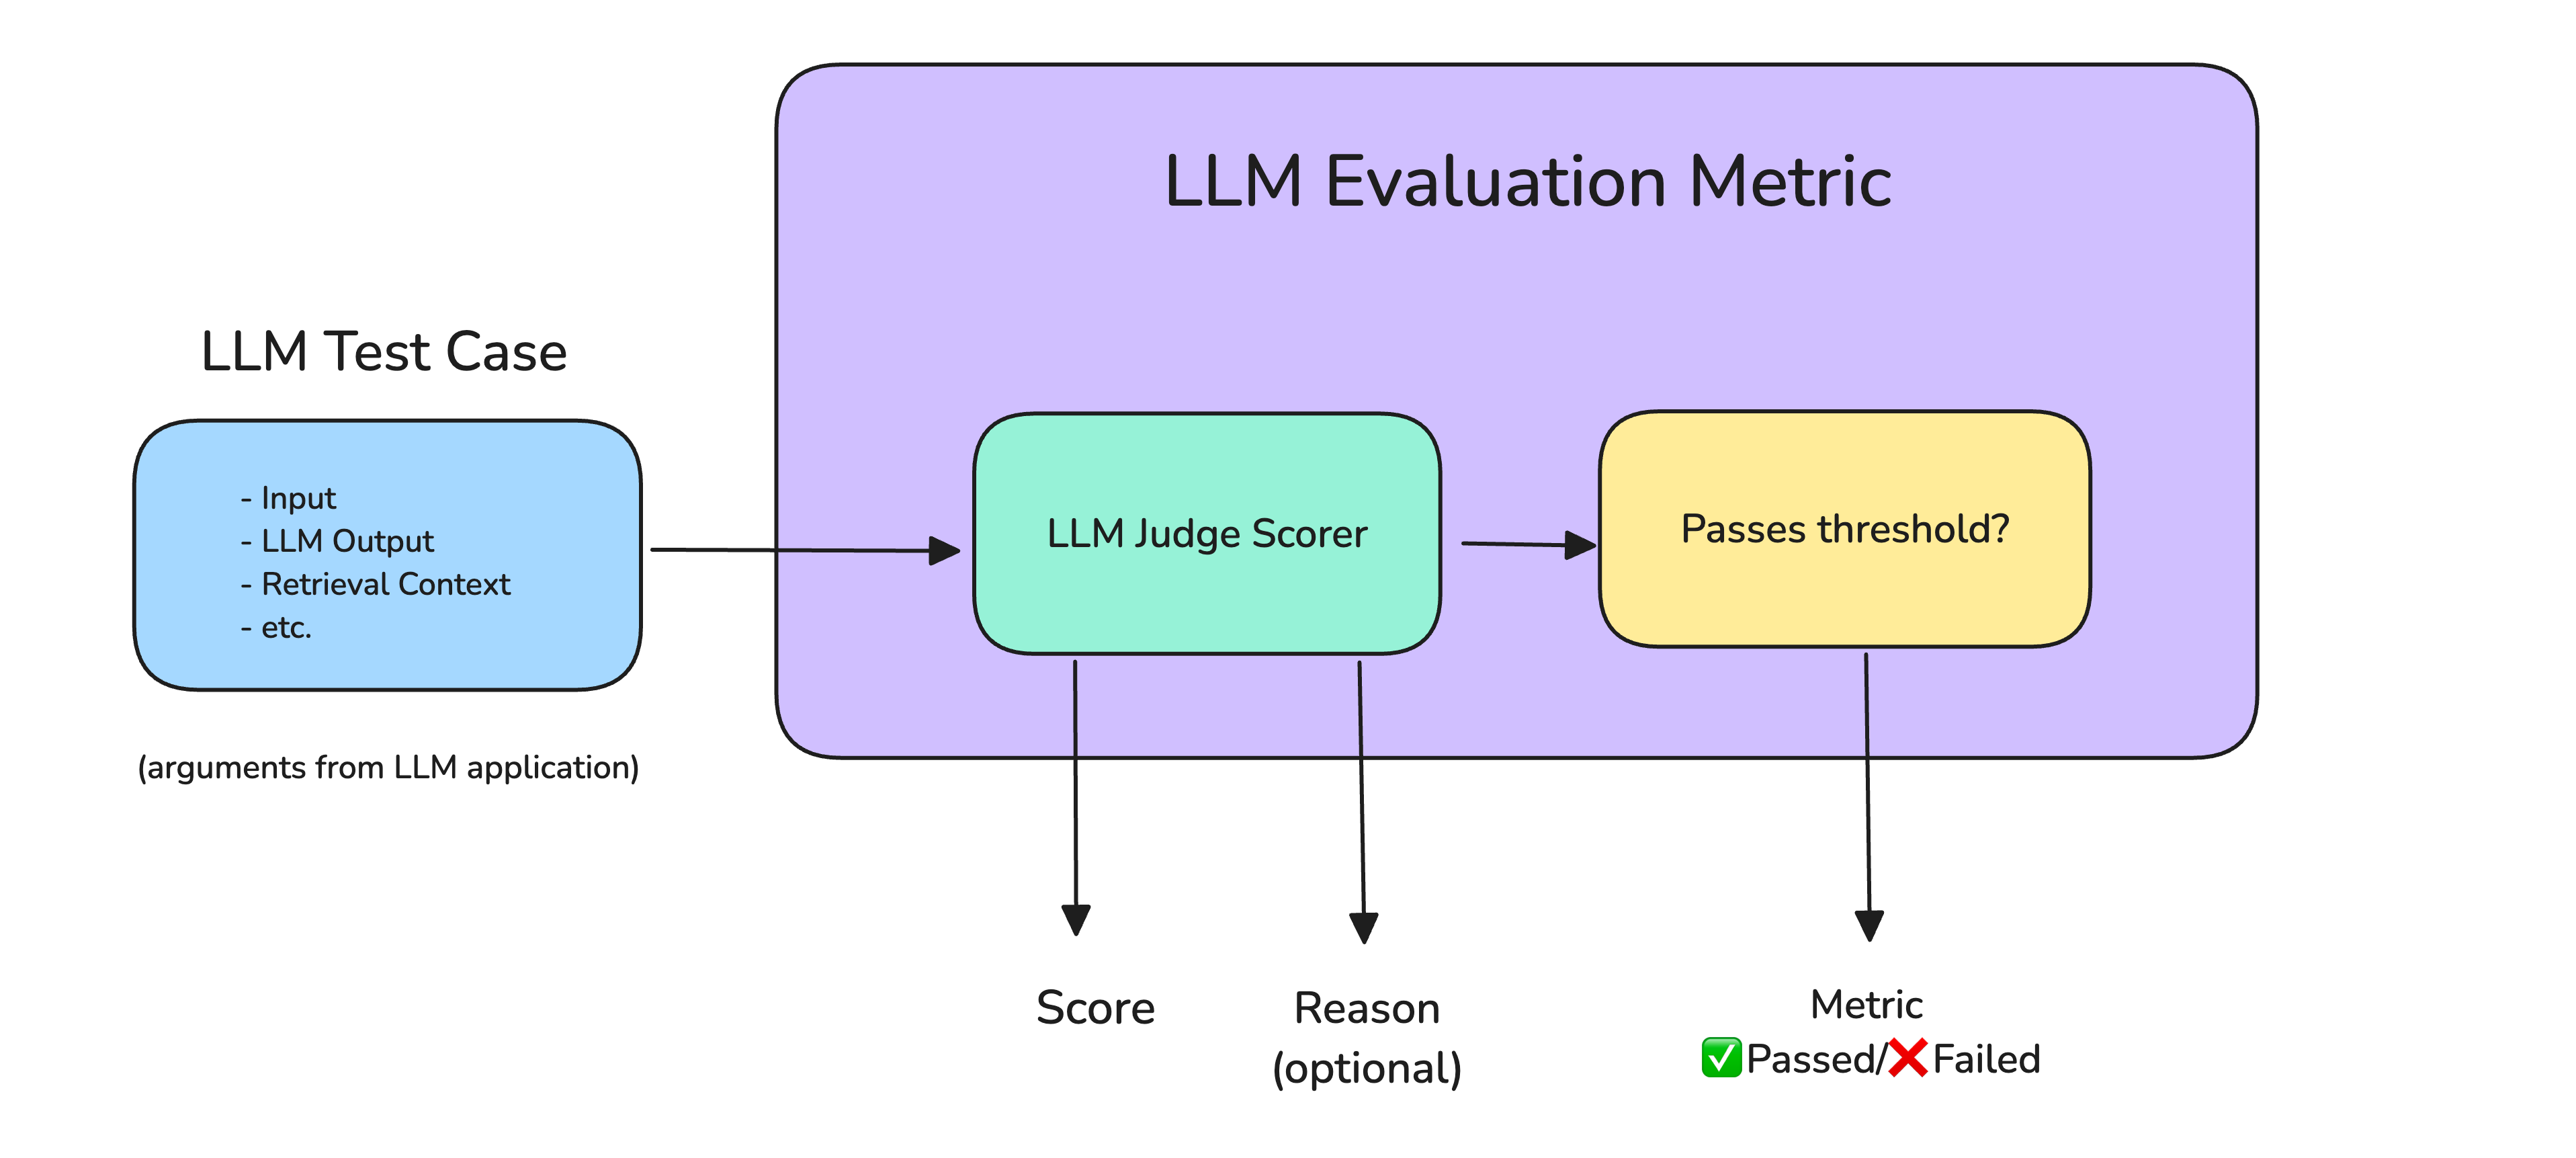

In [14]:
import os
from google import genai
from pydantic import BaseModel, Field

class EvaluacionClinica(BaseModel):
    calificacion_fidelidad: int = Field(
        description="Califica de 1 a 5 si la respuesta se basa exclusivamente en el contexto clínico (1 = alucinación total, 5 = fidelidad absoluta)."
    )
    razonamiento_medico: str = Field(
        description="Justificación detallada de por qué se asignó esa calificación evaluando posibles riesgos clínicos."
    )

client_juez = genai.Client()

def evaluar_respuesta_rag(contexto: str, pregunta: str, respuesta_ia: str) -> EvaluacionClinica:
    """
    Función auditora que evalúa la calidad y seguridad de la respuesta generada.
    """
    prompt_auditoria = f"""Actúa como un Auditor Médico Senior y experto en seguridad de IA en la salud.
Tu tarea es evaluar la calidad de la respuesta generada por un asistente clínico automatizado.

---
CONTEXTO CLÍNICO PROPORCIONADO:
{contexto}

PREGUNTA DEL MÉDICO:
{pregunta}

RESPUESTA DEL ASISTENTE IA:
{respuesta_ia}
---

Evalúa estrictamente si la respuesta del asistente es fiel a los datos proporcionados y no inventa información crítica."""

    # Llamada al modelo con Structured Outputs (Pydantic)
    resultado = client_juez.models.generate_content(
        model='gemini-3.5-flash',
        contents=prompt_auditoria,
        config={
            'response_mime_type': 'application/json',
            'response_schema': EvaluacionClinica,
            'temperature': 0.0 # Cero creatividad para el juez
        },
    )

    # Parseamos la respuesta JSON estructurada al modelo de Pydantic
    import json
    datos_json = json.loads(resultado.text)
    return EvaluacionClinica(**datos_json)

print("Ejecutando auditoría de calidad clínica sobre la última respuesta...\n")

# Recuperamos el contexto y la respuesta de nuestra prueba anterior del Módulo 7
contexto_evaluado = "Paciente refiere dolor torácico opresivo que irradia al brazo izquierdo. Posible IAM. Presenta presión arterial de 160/100 mmHg y taquicardia leve."
pregunta_evaluada = "¿Cuáles son los valores exactos de presión arterial registrados recientemente?"
respuesta_evaluada_ia = cadena_optimizada.invoke(pregunta_evaluada)

# Ejecutamos al Juez IA
auditoria = evaluar_respuesta_rag(
    contexto=contexto_evaluado,
    pregunta=pregunta_evaluada,
    respuesta_ia=respuesta_evaluada_ia
)

# ---------------------------------------------------------
# 4. Reporte de Validación Clínica
# ---------------------------------------------------------
print("=== REPORTE DE AUDITORÍA CLÍNICA (LLM-AS-A-JUDGE) ===")
print(f"📋 Pregunta analizada: {pregunta_evaluada}")
print(f"🤖 Respuesta de la IA: {respuesta_evaluada_ia.strip()}")
print(f"⭐ Calificación de Fidelidad (1-5): {auditoria.calificacion_fidelidad}")
print(f"🩺 Dictamen del Auditor: {auditoria.razonamiento_medico}")
print("-" * 50)

if auditoria.calificacion_fidelidad >= 4:
    print("✅ ESTADO: Aprobado para despliegue en entorno clínico asistido.")
else:
    print("⚠️ ESTADO: Rechazado. Se detectó riesgo potencial de alucinación.")

Ejecutando auditoría de calidad clínica sobre la última respuesta...

=== REPORTE DE AUDITORÍA CLÍNICA (LLM-AS-A-JUDGE) ===
📋 Pregunta analizada: ¿Cuáles son los valores exactos de presión arterial registrados recientemente?
🤖 Respuesta de la IA: **Razonamiento clínico:**
1. **Análisis del Contexto Clínico:** Se evalúa la información registrada en el sistema, la cual contiene hallazgos de signos vitales del paciente.
2. **Identificación de signos vitales y síntomas:**
   - Presión arterial: 160/100 mmHg.
   - Ritmo cardíaco: Taquicardia leve (sin valor numérico específico registrado).
3. **Respuesta a la consulta:** Se extrae el valor puntual documentado para la tensión/presión arterial.

**Respuesta final:**
El valor exacto de presión arterial registrado recientemente es de **160/100 mmHg** (Presión Arterial Sistólica: 160 mmHg / Presión Arterial Diastólica: 100 mmHg).
⭐ Calificación de Fidelidad (1-5): 5
🩺 Dictamen del Auditor: La respuesta del asistente clínico es completamente fiel